# Data Exploration - Possible Asteroid Impacts with Earth

This dataset is a snapshot of data from Sentry, a system that monitors near earth asteroids and predicts their threat.

One row summarizes **one asteroid and its possible impact scenarios** in this
dataset. These are model estimates, not a record of observed collisions.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams.update({"figure.figsize": (10, 6), "axes.grid": False})

In [2]:
data_path = Path("./impacts.csv")
raw = pd.read_csv(data_path, dtype="string")
print("Rows and columns:", raw.shape)
raw.head()

Rows and columns: (683, 11)


,Object Name,Period Start,Period End,Possible Impacts,Cumulative Impact Probability,Asteroid Velocity,Asteroid Magnitude,Asteroid Diameter (km),Cumulative Palermo Scale,Maximum Palermo Scale,Maximum Torino Scale
0,2006 WP1,2017,2017,1,5.2E-09,17.77,28.3,0.007,-8.31,-8.31,0
1,2013 YB,2017,2046,23,7.6E-05,8.98,31.4,0.002,-6.6,-6.96,0
2,2008 US,2017,2062,30,1.6E-05,18.33,31.4,0.002,-6.48,-6.87,0
3,2010 VR139,2017,2076,24,2E-07,4.99,26.7,0.016,-6.83,-6.95,0
4,2015 ME131,2017,2096,85,2.3E-08,19.46,19.2,0.497,-3.85,-4.3,0


### 1. Data preparation
| CSV column → short name | Meaning | Statistical role | Data type |
|---|---|---| --- |
| `Object Name` → `object_name` | Asteroid designation | Identifier | Identifier |
| `Period Start` → `period_start` | Earliest potential-impact year | Calendar year | Date (year; discrete) |
| `Period End` → `period_end` | Latest potential-impact year | Calendar year | Date (year; discrete) |
| `Possible Impacts` → `possible_impacts` | Number of potential impact solutions | Count | Numerical discrete |
| `Cumulative Impact Probability` → `impact_probability` | Combined probability across solutions | Fraction from 0 to 1 | Numerical continuous |
| `Asteroid Velocity` → `velocity_km_s` | Relative speed, km/s | Sentry's excess velocity excludes Earth's gravitational acceleration | Numerical continuous |
| `Asteroid Magnitude` → `absolute_magnitude` | Absolute magnitude H | Brightness scale; smaller H means brighter | Numerical continuous |
| `Asteroid Diameter (km)` → `diameter_km` | Estimated diameter, km | Approximate; often inferred from H and assumed reflectivity | Numerical continuous |
| `Cumulative Palermo Scale` → `palermo_cumulative` | Combined Palermo rating | Logarithmic risk scale | Numerical continuous |
| `Maximum Palermo Scale` → `palermo_max` | Highest individual Palermo rating | Logarithmic risk scale | Numerical continuous |
| `Maximum Torino Scale` → `torino_max` | Highest Torino rating | Ordered category from 0 to 10 | Categorical ordinal |

### Palermo Technical Impact Hazard Scale

The scale compares the likelihood of a detected potential impact with the **background risk** - the average hazard posed by objects of the same size or larger up until the predicted impact date.

Because the scale is **logarithmic**, values translate as follows:

| Palermo Value | What It Means |
| :--- | :--- |
| **-2** | The event is **100 times less likely** (1%) than the random background hazard. |
| **0** | The single event poses **the exact same threat** as the background hazard. |
| **+2** | The event is **100 times more likely** than a random impact by a similar-sized object. |

---

> **In short:** Values below 0 mean no real danger, values between 0 and +2 warrant close monitoring, and anything above +2 means it is time to start worrying (and planning space missions).

### Torino Scale

Adopted by the International Astronomical Union (IAU) in 1999, the **Torino Scale** categorizes potential Earth impact hazards using an integer scale from **0 to 10** alongside intuitive color coding. It combines both **likelihood** and **consequences** into a single rating designed for clear public communication-though it ignores how much time is left until the potential impact.

---

### Hazard Levels & Color Codes

| Value | Category | Description |
| :---: | :--- | :--- |
| **0** | **White / Green** | **No Hazard:** Likelihood of impact is effectively zero, or object is too small to survive atmospheric entry. |
| **1** | **Green** | **Normal:** Routine discovery. Impact is extremely unlikely, with standard tracking expected to reclassify it to 0. |
| **2 – 4** | **Yellow** | **Merits Attention:** Close pass requiring careful monitoring by astronomers. Risk remains relatively low. |
| **5 – 7** | **Orange** | **Threatening:** Critical close encounter. High probability of significant regional or global devastation. |
| **8 – 10** | **Red** | **Certain Collisions:** Confirmed impact capable of causing local destruction (8), regional disaster (9), or global catastrophe (10). |

---

> **TL;DR:** 0 is "go back to sleep", 1–4 is "astronomers doing math", 5–7 is "sweaty palms", and 8–10 is full-on Hollywood movie scenario.


In [3]:
# Preparing the dataset: renaming columns to simpler names, converting numeric columns from string to float/int
column_names = {
    "Object Name": "object_name",
    "Period Start": "period_start",
    "Period End": "period_end",
    "Possible Impacts": "possible_impacts",
    "Cumulative Impact Probability": "impact_probability",
    "Asteroid Velocity": "velocity_km_s",
    "Asteroid Magnitude": "absolute_magnitude",
    "Asteroid Diameter (km)": "diameter_km",
    "Cumulative Palermo Scale": "palermo_cumulative",
    "Maximum Palermo Scale": "palermo_max",
    "Maximum Torino Scale": "torino_max",
}

asteroids = raw.copy()
asteroids.columns = asteroids.columns.str.strip()
asteroids = asteroids.rename(columns=column_names)

# Convert numeric columns to float/int with a built-in data quality audit
numeric_columns = [col for col in column_names.values() if col != "object_name"]
conversion_failures = {}

for col in numeric_columns:
    # 1. Clean whitespace and treat empty strings as missing values
    text = asteroids[col].str.strip().replace("", pd.NA)

    # 2. Safely parse to numbers; non-numeric values (e.g. '(*)') become NaN instead of crashing
    converted = pd.to_numeric(text, errors="coerce")

    # 3. count non-empty cells that failed parsing (notna originally, but converted to NaN)
    conversion_failures[col] = int((text.notna() & converted.isna()).sum())

    # 4. Store the cleaned numeric column back into the dataframe
    asteroids[col] = converted


In [4]:
print("Non-empty values that could not be parsed (inspect raw if any are nonzero):")
pd.Series(conversion_failures, name="conversion_failures")

Non-empty values that could not be parsed (inspect raw if any are nonzero):


period_start          0
period_end            0
possible_impacts      0
impact_probability    0
velocity_km_s         0
absolute_magnitude    0
diameter_km           0
palermo_cumulative    0
palermo_max           0
torino_max            3
Name: conversion_failures, dtype: int64

In [5]:
asteroids.loc[asteroids["torino_max"].isna()]

,object_name,period_start,period_end,possible_impacts,impact_probability,velocity_km_s,absolute_magnitude,diameter_km,palermo_cumulative,palermo_max,torino_max
680,101955 Bennu (1999 RQ36),2175,2199,78,0.00037,5.99,20.2,0.49,-1.71,-2.32,<NA>
681,410777 (2009 FD),2185,2198,7,0.0016,15.87,22.1,0.16,-1.78,-1.83,<NA>
682,29075 (1950 DA),2880,2880,1,0.00012,14.1,17.6,1.3,-1.42,-1.42,<NA>


There are 3 records with `torino_max` set to a non-numeric value `(*)`. In NASA Sentry documentation, this symbol indicates a special, retired, or re-evaluated status (e.g. for famous objects like 1950 DA and Bennu whose impact solutions extend centuries into the future). These values become `NaN` during numeric coercion.

#### Understand the table and check data quality

In [6]:
print("Rows and columns:", asteroids.shape)

Rows and columns: (683, 11)


In [7]:
quality = pd.DataFrame({
    "dtype": asteroids.dtypes.astype(str),
    "missing_count": asteroids.isna().sum(),
    "missing_percent": asteroids.isna().mean().mul(100).round(2),
    "unique_values": asteroids.nunique(),
})
quality

,dtype,missing_count,missing_percent,unique_values
object_name,string,0,0.00,683
period_start,Int64,0,0.00,102
period_end,Int64,0,0.00,93
possible_impacts,Int64,0,0.00,140
impact_probability,Float64,0,0.00,340
velocity_km_s,Float64,0,0.00,571
absolute_magnitude,Float64,0,0.00,118
diameter_km,Float64,0,0.00,122
palermo_cumulative,Float64,0,0.00,392
palermo_max,Float64,0,0.00,378


In [8]:
print("Identical rows:", asteroids.duplicated().sum())
print("Repeated non-missing object names:",
      asteroids["object_name"].dropna().duplicated().sum())

Identical rows: 0
Repeated non-missing object names: 0


**Flag questionable values** - create a table, where each row describes if the same row of `asteroids` has questionable values

In [9]:
flags = pd.DataFrame(index=asteroids.index)
p = asteroids["impact_probability"]
flags["probability_outside_0_1"] = (p < 0) | (p > 1)
flags["nonpositive_diameter"] = asteroids["diameter_km"] <= 0
flags["negative_velocity"] = asteroids["velocity_km_s"] < 0
flags["reversed_year_range"] = asteroids["period_start"] > asteroids["period_end"]
for name in ["period_start", "period_end", "possible_impacts", "torino_max"]:
    flags[f"{name}_not_integer"] = asteroids[name].mod(1).ne(0)
flags["negative_impact_count"] = asteroids["possible_impacts"] < 0
# Torino scale is defined only for impacts within the next ~100 years.
# All three objects with a '*' entry represent very long‑term solutions.
# We treat these NaNs as “outside the 0‑10 range” so they are flagged, but later we simply ignore
# the Torino column for the filtered subset.
flags["torino_outside_0_10"] = ~asteroids["torino_max"].between(0, 10)

In [10]:
flags.sum().rename("flagged_rows")

probability_outside_0_1         0
nonpositive_diameter            0
negative_velocity               0
reversed_year_range             0
period_start_not_integer        0
period_end_not_integer          0
possible_impacts_not_integer    0
torino_max_not_integer          0
negative_impact_count           0
torino_outside_0_10             0
Name: flagged_rows, dtype: Int64

The data validation confirms that the dataset is exceptionally clean: all physical measurements (diameter, velocity, probability) fall within physically valid intervals. The only flagged rows correspond to the 3 non-numeric `(*)` entries in `torino_max`.

### 2. Distributions and relationships

**Initial expectations & predictions:**
- **Asteroid size:** I expect a strong right-skewed distribution. In nature, smaller fragments and pebbles are exponentially more common than massive kilometer-scale asteroids.
- **Impact probability:** I expect probabilities to be heavily clustered near zero ($10^{-6}$ to $10^{-4}$), with very few high-probability outliers. If large asteroids had high impact probabilities, they would be breaking global news.
- **Size vs. Impact probability:** We expect little to no correlation between size and probability. An asteroid's chance of hitting Earth is dictated by orbital intersection geometry, not by how large the object is.
- **Size vs. Brightness (Magnitude):** I expect a strong inverse relationship between diameter and absolute magnitude $H$, because larger physical bodies reflect more sunlight, and astronomical magnitude uses a reverse scale (smaller $H$ = brighter).

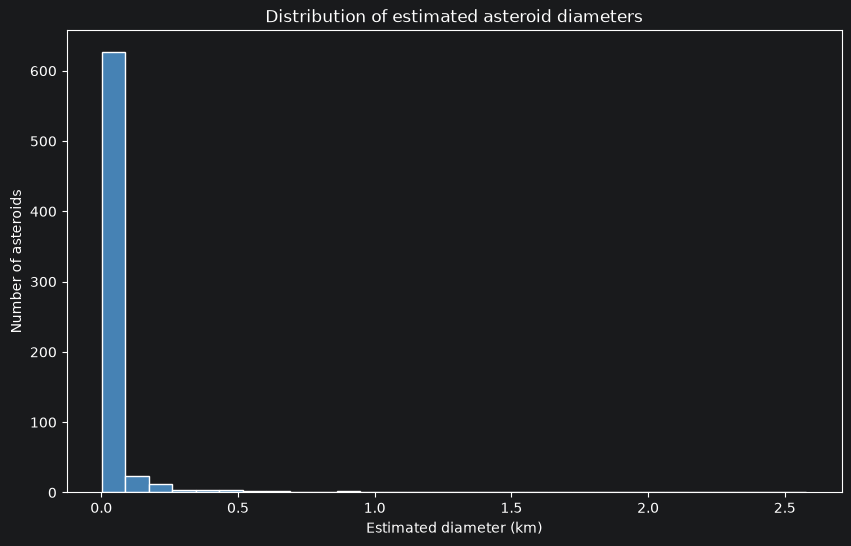

In [11]:
fig, ax = plt.subplots()
ax.hist(asteroids["diameter_km"], bins=30, color="steelblue", edgecolor="white")
ax.set(xlabel="Estimated diameter (km)", ylabel="Number of asteroids",
       title="Distribution of estimated asteroid diameters")
plt.show()

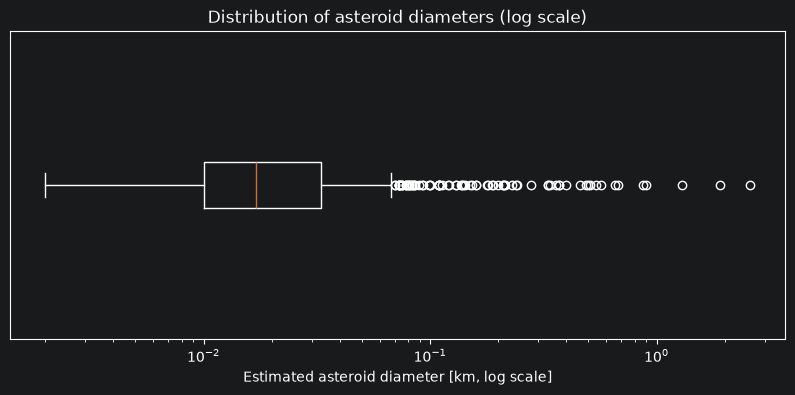

In [12]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot(asteroids["diameter_km"], orientation="horizontal")
ax.semilogx()
ax.set_xlabel("Estimated asteroid diameter [km, log scale]")
ax.set_yticks([])
ax.set_title("Distribution of asteroid diameters (log scale)")
plt.show()

## What a boxplot tells us about asteroid diameters

- The **box** spans the inter‑quartile range (IQR): 25% of asteroids have diameters below the lower edge, 25% above the upper edge.
- The median (0.017km).
- **Whiskers** extend to the most extreme values that are not considered outliers (by default 1.5×IQR). In our data they reach ~0.1km because the distribution is heavily right‑skewed.
- Points beyond the whiskers are plotted as individual **circles** – they represent the few very large asteroids (e.g., the ~2.5km object).

**Interpretation:**
Most asteroids cluster near the left side of the plot (tiny diameters). The long whisker and the outlier markers on the right show that a small number of objects are orders of magnitude larger than the rest, which is exactly what a right‑skewed distribution looks like.





In [13]:
# >0 indicates right skew, <0 indicates left skew
print(f"Skewness of asteroid diameter: {asteroids['diameter_km'].skew():.2f}")
asteroids.describe()

Skewness of asteroid diameter: 10.37


,period_start,period_end,possible_impacts,impact_probability,velocity_km_s,absolute_magnitude,diameter_km,palermo_cumulative,palermo_max,torino_max
count,683.0,683.0,683.0,683.0,683.0,683.0,683.0,683.0,683.0,680.0
mean,2062.573939,2099.68082,43.348463,0.000154,11.462577,26.158272,0.049378,-6.511552,-6.804012,0.0
std,43.501694,37.594698,113.77328,0.00252,6.067772,2.388296,0.156403,1.509189,1.476135,0.0
min,2017.0,2017.0,1.0,0.0,0.34,15.6,0.002,-10.98,-11.0,0.0
25%,2034.0,2090.0,2.0,0.0,7.24,25.0,0.01,-7.49,-7.79,0.0
50%,2061.0,2109.0,6.0,0.000002,10.5,26.4,0.017,-6.46,-6.79,0.0
75%,2085.0,2114.0,29.0,0.000016,14.81,27.8,0.033,-5.49,-5.865,0.0
max,2880.0,2880.0,1144.0,0.065,39.47,31.6,2.579,-1.42,-1.42,0.0


- **Right‑skewed distribution**: Most asteroids are *tiny* and only a few are *very large*.
- **Skewness ≈10.9**: saying the right‑hand tail is *extremely* long compared to the bulk of the data.
- **Median diameter (0.017km)**: Half of the 683 tracked asteroids are smaller than 17m. The other half are larger, but many are still only a few tens of metres.
- **Largest asteroid >2.5km**: The biggest object in the catalog is more than **150 times larger** than the median size – comparable to a small mountain.
- **Implication**: Small near‑Earth objects dominate the population by sheer numbers, while large asteroids are rare. Most of the tiny ones would burn up in Earth’s atmosphere, whereas only the few large ones could cause significant damage if they ever hit the planet.

*In short, the size data tell us that the asteroid crowd is made up of a huge number of little rocks and only a handful of truly big ones.*


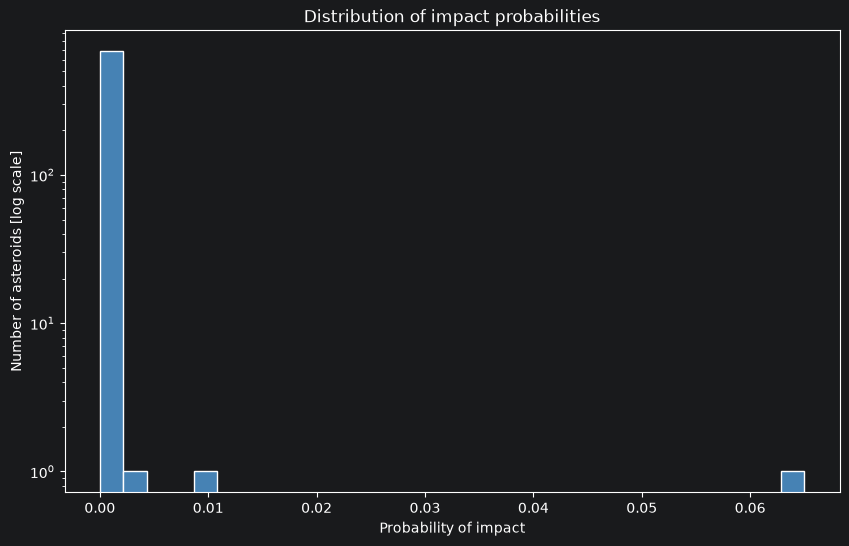

In [14]:
fig, ax = plt.subplots()
ax.hist(asteroids["impact_probability"], bins=30, color="steelblue", edgecolor="white")
ax.set(xlabel="Probability of impact", ylabel="Number of asteroids [log scale]",
       title="Distribution of impact probabilities")
ax.semilogy()
plt.show()

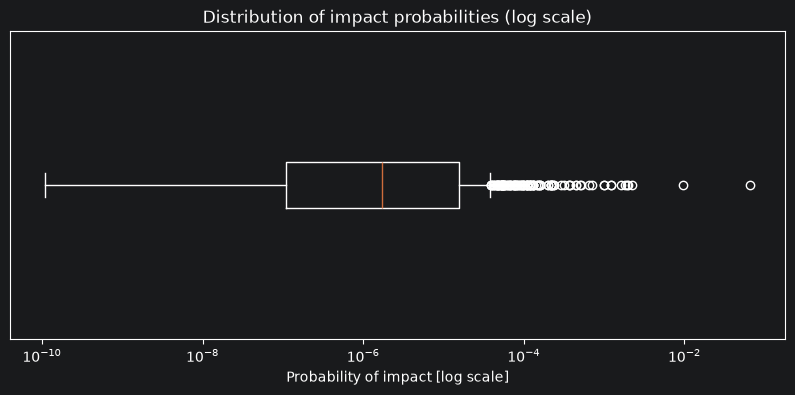

In [15]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot(asteroids["impact_probability"], orientation="horizontal")
ax.semilogx()
ax.set_xlabel("Probability of impact [log scale]")
ax.set_yticks([])
ax.set_title("Distribution of impact probabilities (log scale)")
plt.show()

My expectation about impact probabilities was accurate: the vast majority of cumulative probabilities are extraordinarily tiny (between $10^{-7}$ and $10^{-5}$), with a median of $1.7 \times 10^{-6}$. Only a tiny fraction of outliers exceed $10^{-2}$ (such as 2010 RF12 with a $\sim 6.5\%$ cumulative probability).

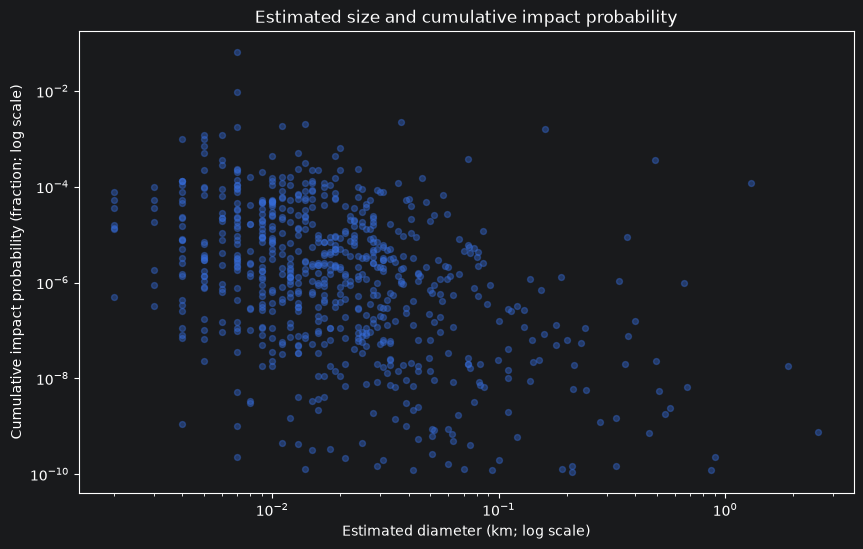

Correlation: -0.0136


In [16]:
fig, ax = plt.subplots()
ax.scatter(asteroids["diameter_km"], asteroids["impact_probability"], s=18, alpha=0.4)
ax.set(
    xscale="log",
    yscale="log",
    xlabel="Estimated diameter (km; log scale)",
    ylabel="Cumulative impact probability (fraction; log scale)",
    title="Estimated size and cumulative impact probability",
)
plt.show()

# Korelacja Pearsona na surowych danych
corr = asteroids["diameter_km"].corr(asteroids["impact_probability"])
print(f"Correlation: {corr:.4f}")


The scatter plot confirms my expectation: there is virtually no correlation between an asteroid's physical size and its cumulative impact probability ($r \approx -0.01$). Orbital alignment is governed by celestial mechanics and orbital resonances, completely independent of whether the body is 10 meters or 1 kilometer across.

The computed coefficient is **r ≈ -0.0136**, essentially zero.
This confirms that the physical *size* of an asteroid does **not** predict how likely it is to hit Earth-its impact probability is controlled entirely by orbital dynamics.


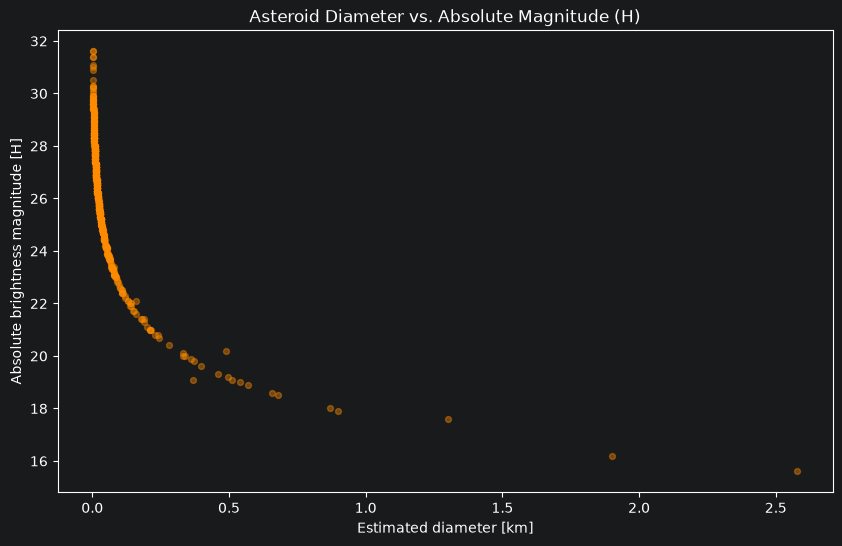

In [17]:
fig, ax = plt.subplots()
ax.scatter(asteroids["diameter_km"], asteroids["absolute_magnitude"], s=18, alpha=0.4, color="darkorange")
ax.set_xlabel("Estimated diameter [km]")
ax.set_ylabel("Absolute brightness magnitude [H]")
ax.set_title("Asteroid Diameter vs. Absolute Magnitude (H)")
plt.show()

The overall negative slope validates that the dataset follows the expected physical relationship between size and brightness. Any points that deviate strongly (e.g., very large diameters with high H) are candidates for further inspection-perhaps diameter estimate is noisy.

### 3. Impact risk analysis

**Expectations before inspecting risk scales:**
- The Torino scale is an integer scale from 0 to 10. I expect almost all entries to be 0 because no known object has an immediate high-probability collision trajectory.
- The Palermo technical scale compares impact hazard against background risk. I expect larger asteroids to achieve higher Palermo ratings even if their collision probability is low, because the background impact rate of large bodies is astronomically small.

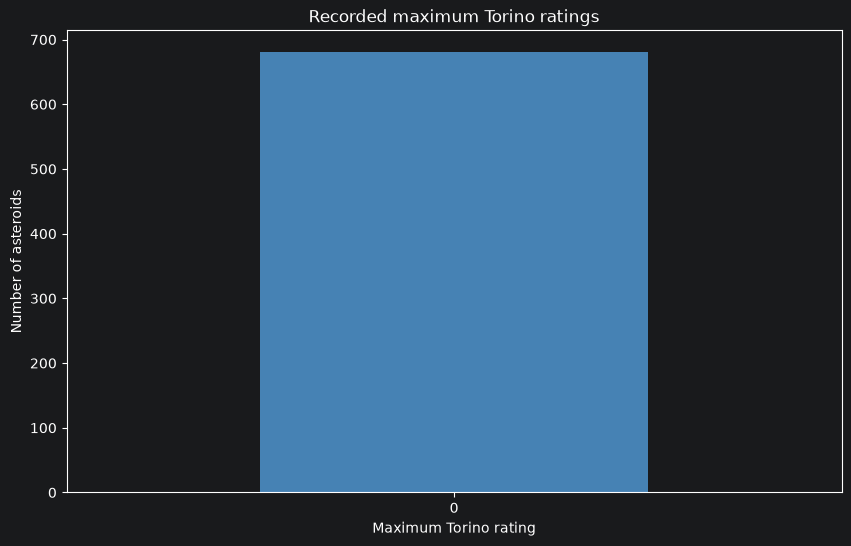

In [18]:
torino_counts = asteroids["torino_max"].value_counts().sort_index()
fig, ax = plt.subplots()
torino_counts.plot.bar(ax=ax, color="steelblue", rot=0)
ax.set(xlabel="Maximum Torino rating", ylabel="Number of asteroids",
       title="Recorded maximum Torino ratings")
plt.show()

Every single parsed asteroid in the catalog has a Torino rating of 0. This illustrates the limitation of the Torino scale for scientific differentiation: while reassuring for public safety (no object poses a certain short-term collision), it provides zero granularity for prioritizing research or telescopic tracking.

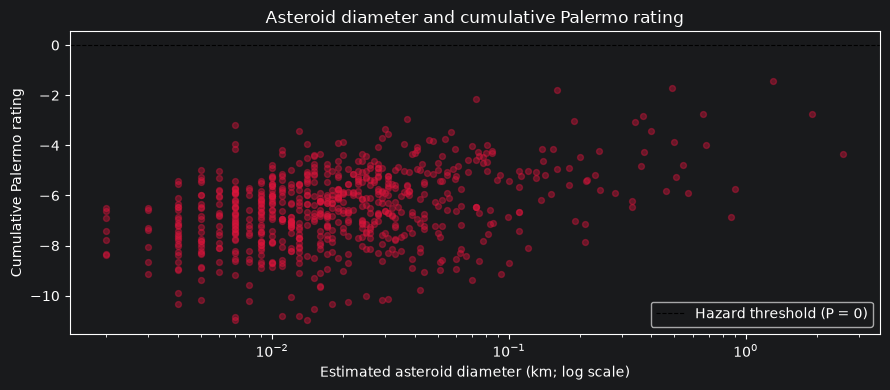

Correlation between diameter and Palermo rating:
0.2675899723748633


In [19]:
plot_mask = (
    (asteroids["diameter_km"] > 0)
    & np.isfinite(asteroids["diameter_km"])
    & np.isfinite(asteroids["palermo_cumulative"])
).fillna(False)
plot_data = asteroids.loc[plot_mask]

fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(plot_data["diameter_km"], plot_data["palermo_cumulative"], s=18, alpha=0.4, color="crimson")
ax.axhline(0, color="black", linewidth=0.8, linestyle="--", label="Hazard threshold (P = 0)")
ax.set_xscale("log")
ax.set_xlabel("Estimated asteroid diameter (km; log scale)")
ax.set_ylabel("Cumulative Palermo rating")
ax.set_title("Asteroid diameter and cumulative Palermo rating")
ax.legend()
fig.tight_layout()
plt.show()
print("Correlation between diameter and Palermo rating:")
print(plot_data.corr(numeric_only=True)["diameter_km"]["palermo_cumulative"])

The scatter plot reveals a weak-to-moderate positive linear correlation between an asteroid's physical size and its cumulative Palermo rating ($r \approx 0.27$).

Unlike pure impact probability, the Palermo scale explicitly factors in kinetic energy and target mass—meaning larger objects carry inherently higher baseline hazard scores. However, because impact probability still dominates the scale's calculation and varies dramatically across objects, physical size alone remains a relatively poor single predictor of overall Palermo risk.

**Pearson correlation (diameter vs cumulative Palermo rating)**
The computed coefficient is **r ≈ 0.268**, showing a weak positive relationship.
While larger asteroids pose greater potential consequences, their Palermo hazard score is heavily tempered by their actual likelihood of hitting Earth.

The scatter plot reveals a weak-to-moderate positive linear correlation between an asteroid's physical size and its cumulative Palermo rating ($r \approx 0.27$).

Unlike pure impact probability, the Palermo scale explicitly factors in kinetic energy and target mass—meaning larger objects carry inherently higher baseline hazard scores. However, because impact probability still dominates the scale's calculation and varies dramatically across objects, physical size alone remains a relatively poor single predictor of overall Palermo risk.

**Pearson correlation (diameter vs cumulative Palermo rating)**
The computed coefficient is **r ≈ 0.268**, showing a weak positive relationship.
While larger asteroids pose greater potential consequences, their Palermo hazard score is heavily tempered by their actual likelihood of hitting Earth.